# Gas Classification under Sensor Drift
### Fundamentals of Machine Learning (IT5022) - Assignment

Supervised multiclass classification of 6 gases from 128 sensor-response features,
comparing Logistic Regression and Random Forest. Dataset: Gas Sensor Array Drift at
Different Concentrations (UCI ML Repository, ID 270).

---

### Problem
A 16-sensor metal-oxide array gives 128 features per reading, and we want to tell which
of six gases it is. These sensors drift over months, so we also check how a model trained
on early data holds up on data collected later.

### How we set things up
We load the original UCI `.dat` files so each reading keeps its true batch number from the
filename. All preprocessing (scaling, feature selection, PCA) is fit on training data only,
and inside cross-validation it is re-fit within each fold using a `Pipeline` so nothing leaks
from validation data. Model and hyper-parameter choices are made from training-set
cross-validation. We use two separate tests: a normal random 75/25 split, and a chronological
test that trains on early batches and evaluates on later ones.

In [1]:
# --- Run once if these libraries are not already installed ---
# %pip install numpy pandas matplotlib seaborn scikit-learn

## 1. Imports, Configuration and Helpers

In [2]:
import io, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler, FunctionTransformer, label_binarize
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import f_classif, mutual_info_classif, SelectKBest
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             precision_score, recall_score, roc_auc_score,
                             confusion_matrix, classification_report)

# Warnings are intentionally NOT globally silenced, so genuine issues
# (e.g. non-convergence) remain visible.

RANDOM_STATE = 42
sns.set_style("whitegrid")
%matplotlib inline
np.random.seed(RANDOM_STATE)

# Final models (reported). A lighter forest is used ONLY inside CV/tuning loops for speed;
# this is stated wherever it is used.
def make_lr():       return LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
def make_rf():       return RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                   class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)
def make_rf_light(): return RandomForestClassifier(n_estimators=80, min_samples_leaf=2,
                                                   class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE)

CV5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
CV3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

def multiclass_scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Macro-Prec": precision_score(y_true, y_pred, average="macro"),
            "Macro-Recall": recall_score(y_true, y_pred, average="macro"),
            "Macro-F1": f1_score(y_true, y_pred, average="macro"),
            "Balanced-Acc": balanced_accuracy_score(y_true, y_pred)}

## 2. Load the dataset from the original UCI `.dat` files

Canonical source: **UCI ML Repository, ID 270**
(`https://archive.ics.uci.edu/dataset/270/gas+sensor+array+drift+at+different+concentrations`).

The dataset ships as ten files, `batch1.dat … batch10.dat`, one per acquisition period, in a
sparse `class;concentration index:value …` format. **Taking the batch number from the filename
guarantees the correct chronological order** — important for the drift study, and more reliable
than a pre-flattened CSV whose batch column could be re-ordered. We download and parse them
below (if the files are already in `./data/`, those are used instead). The `.dat` files are fetched from a public **GitHub mirror** of the UCI files; the canonical source remains UCI ID 270.

Numeric class labels map to gases per the UCI documentation
(1=Ethanol, 2=Ethylene, 3=Ammonia, 4=Acetaldehyde, 5=Acetone, 6=Toluene).

In [3]:
GAS = {1:"Ethanol", 2:"Ethylene", 3:"Ammonia", 4:"Acetaldehyde", 5:"Acetone", 6:"Toluene"}
BASE = "https://raw.githubusercontent.com/HakanKARASU/Gas-Sensor-Array-Drift-Dataset/main/"
FEATURES = [f"feature_{i}" for i in range(1, 129)]

def parse_dat(lines):
    labels, concs, feats = [], [], []
    for line in lines:
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        cls, conc = parts[0].split(";")            # 'class;concentration'
        row = np.zeros(128)
        for tok in parts[1:]:
            idx, val = tok.split(":")
            row[int(idx)-1] = float(val)
        labels.append(int(cls)); concs.append(float(conc)); feats.append(row)
    return np.array(feats), np.array(labels), np.array(concs)

def load_batch(b):
    local = Path("data")/f"batch{b}.dat"
    if local.exists():
        with open(local) as f: lines = f.readlines()
    else:
        lines = urllib.request.urlopen(BASE + f"batch{b}.dat").read().decode().splitlines()
    X, y, conc = parse_dat(lines)
    dfb = pd.DataFrame(X, columns=FEATURES)
    dfb["gas"] = [GAS[c] for c in y]
    dfb["batch"] = b                                # true chronological batch from filename
    dfb["concentration"] = conc                     # METADATA only - never used as a predictor
    return dfb

df = pd.concat([load_batch(b) for b in range(1, 11)], ignore_index=True)
print("Loaded shape:", df.shape)
df.head(3)

Loaded shape: (13910, 131)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_122,feature_123,feature_124,feature_125,feature_126,feature_127,feature_128,gas,batch,concentration
0,15596.1621,1.868245,2.371604,2.803678,7.512213,-2.739388,-3.344671,-4.847512,15326.6914,1.768526,...,3.972203,0.527291,0.728443,1.445783,-0.545079,-0.902241,-2.654529,Ethanol,1,10.0
1,26402.0704,2.532401,5.411209,6.509906,7.658469,-4.722217,-5.817651,-7.518333,23855.7812,2.164706,...,4.281373,0.980205,1.628050,1.951172,-0.889333,-1.323505,-1.749225,Ethanol,1,20.0
2,42103.5820,3.454189,8.198175,10.508439,11.611003,-7.668313,-9.478675,-12.230939,37562.3008,2.840403,...,5.396827,1.403973,2.476956,3.039841,-1.334558,-1.993659,-2.348370,Ethanol,1,30.0


In [4]:
# Validate against the documented UCI ten-batch counts (total 13,910)
expected = {1:445, 2:1244, 3:1586, 4:161, 5:197, 6:2300, 7:3613, 8:294, 9:470, 10:3600}
counts = df["batch"].value_counts().sort_index().to_dict()
print("Per-batch counts match UCI documentation:", counts == expected)
print("Total rows:", len(df), "| Missing values:", int(df[FEATURES].isna().sum().sum()))

Per-batch counts match UCI documentation: True
Total rows: 13910 | Missing values: 0


## 3. Dataset description and audit

Recorded at UC San Diego over **36 months (2008–2011)** with **16 metal-oxide sensors**, each
summarised by **8 features → 128 features**. 13,910 measurements, 6 gases, 10 time batches.
Licence CC BY 4.0.

*Citation: Vergara, A. et al. (2012). Gas Sensor Array Drift Dataset at Different
Concentrations. UCI ML Repository. https://doi.org/10.24432/C5MK6M*

A key audit for the drift study is the **class-by-batch table** - we must check every gas is
present in both the early and later periods, or a chronological split could become unlearnable.

In [5]:
print("Gas class counts:\n", df["gas"].value_counts(), "\n")
print("Feature scale (min .. max): {:.0f} .. {:.0f}".format(df[FEATURES].values.min(), df[FEATURES].values.max()))
print("Most skewed features:\n", df[FEATURES].skew().abs().sort_values(ascending=False).head(3).round(1), "\n")
print("Class-by-batch (chronological):")
pd.crosstab(df["batch"], df["gas"])

Gas class counts:
 gas
Acetone         3009
Ethylene        2926
Ethanol         2565
Acetaldehyde    1936
Toluene         1833
Ammonia         1641
Name: count, dtype: int64 

Feature scale (min .. max): -23661 .. 670687
Most skewed features:
 feature_42    117.9
feature_58    117.8
feature_50    117.3
dtype: float64 

Class-by-batch (chronological):


gas,Acetaldehyde,Acetone,Ammonia,Ethanol,Ethylene,Toluene
batch,,,,,,
1,30,70,83,90,98,74
2,109,532,100,164,334,5
3,240,275,216,365,490,0
4,30,12,12,64,43,0
5,46,63,20,28,40,0
6,29,606,110,514,574,467
7,744,630,360,649,662,568
8,33,143,40,30,30,18
9,75,78,100,61,55,101


> **Audit notes.** No missing values; mild class imbalance (so macro-averaged metrics are
> preferred); features span ~6 orders of magnitude with heavy skew (→ standardisation is
> essential). All six gases appear across the early and late batches, so a chronological split
> remains a valid six-class problem. Batch sizes are very uneven, which matters when averaging
> per-batch scores later.

## 4. Exploratory data analysis

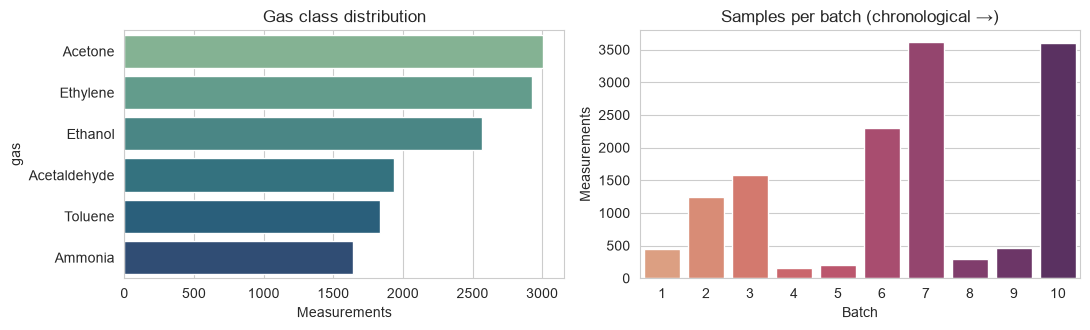

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
vc = df["gas"].value_counts()
sns.barplot(x=vc.values, y=vc.index, hue=vc.index, palette="crest", legend=False, ax=ax[0])
ax[0].set_title("Gas class distribution"); ax[0].set_xlabel("Measurements")
bs = df["batch"].value_counts().sort_index()
sns.barplot(x=bs.index.astype(str), y=bs.values, hue=bs.index.astype(str), palette="flare", legend=False, ax=ax[1])
ax[1].set_title("Samples per batch (chronological \u2192)"); ax[1].set_xlabel("Batch"); ax[1].set_ylabel("Measurements")
plt.tight_layout(); plt.show()

### 4.1 Gas-class composition across batches (Figure B)

The drift study trains on early batches and tests on later ones, so we must know whether the
*class mix itself* changes over time - otherwise an accuracy drop could be blamed on drift when it
is really a composition change. The 100%-stacked bar makes any shift visible.

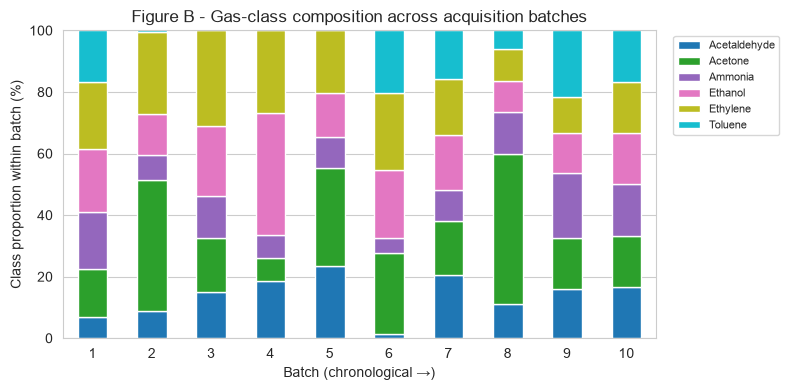

In [7]:
comp = (pd.crosstab(df["batch"], df["gas"], normalize="index") * 100)
comp = comp[sorted(comp.columns)]
comp.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="tab10")
plt.ylabel("Class proportion within batch (%)"); plt.xlabel("Batch (chronological \u2192)")
plt.title("Figure B - Gas-class composition across acquisition batches")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

### 4.2 Concentration as a confounder (metadata, not a feature)

Each measurement has a gas **concentration** (ppmv, per the UCI documentation). We keep it only as
*metadata* - it is **never** a model input (`X = df[FEATURES]` uses the 128 sensor features alone).
If concentration distributions differ across batches, an accuracy drop on later batches could be
partly a concentration effect rather than pure sensor drift - important context for the drift study.

Median concentration (ppmv) by batch:
batch
1     125.0
2     175.0
3     150.0
4     100.0
5     200.0
6      50.0
7     110.0
8     100.0
9     100.0
10    150.0


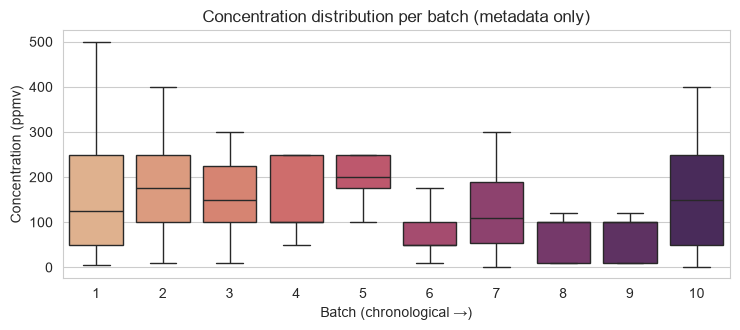

In [8]:
print("Median concentration (ppmv) by batch:")
print(df.groupby("batch")["concentration"].median().round(1).to_string())
plt.figure(figsize=(7.5, 3.4))
sns.boxplot(data=df, x="batch", y="concentration", hue="batch", palette="flare", legend=False, showfliers=False)
plt.title("Concentration distribution per batch (metadata only)")
plt.xlabel("Batch (chronological \u2192)"); plt.ylabel("Concentration (ppmv)")
plt.tight_layout(); plt.show()

## 5. Train/test split

A **stratified 75/25 split** for the random-split protocol. Everything learned from data is fit
on the training part only; the test part is untouched until the final evaluation (Section 14).

In [9]:
X = df[FEATURES].copy()
y = df["gas"].values
batch = df["batch"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (10432, 128)  Test: (3478, 128)


### 5.0 Feature redundancy - correlation heatmap (Figure A)

Many sensor-response features are strongly correlated, which is what motivates both correlation-aware
feature selection and PCA. We show a readable subset (the first three sensors = 24 features),
computed on the **training set** so nothing is learned from held-out data.

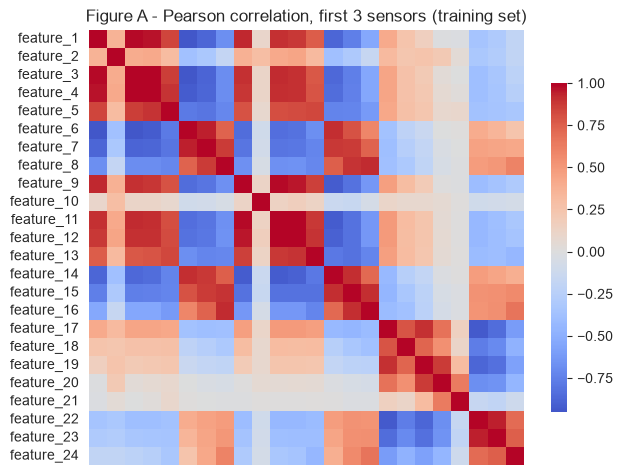

In [10]:
subset = [f"feature_{i}" for i in range(1, 25)]   # first 3 sensors x 8 features
plt.figure(figsize=(6.5, 5.2))
sns.heatmap(X_train[subset].corr(), cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": .7}, xticklabels=False)
plt.title("Figure A - Pearson correlation, first 3 sensors (training set)")
plt.tight_layout(); plt.show()

### 5.1 Does standardisation help? (training-only cross-validation)

We compare Logistic Regression with and without scaling using **CV on the training set** (not the
test set), so this is a fair, leakage-free check and the first step in *how accuracy is obtained*. The unscaled model may emit convergence warnings - that is itself evidence that unscaled, six-orders-of-magnitude features hinder the optimiser; its accuracy is not that of a fully converged model.

In [11]:
lr_noscale = Pipeline([("model", make_lr())])
lr_scaled  = Pipeline([("scale", StandardScaler()), ("model", make_lr())])
s0 = cross_val_score(lr_noscale, X_train, y_train, cv=CV3, scoring="accuracy", n_jobs=-1)
s1 = cross_val_score(lr_scaled,  X_train, y_train, cv=CV3, scoring="accuracy", n_jobs=-1)
print(f"LR CV accuracy WITHOUT scaling : {s0.mean():.4f} +/- {s0.std():.4f}")
print(f"LR CV accuracy WITH scaling    : {s1.mean():.4f} +/- {s1.std():.4f}")
print(f"Improvement from standardisation: {s1.mean()-s0.mean():+.4f}")

LR CV accuracy WITHOUT scaling : 0.9780 +/- 0.0013
LR CV accuracy WITH scaling    : 0.9885 +/- 0.0011
Improvement from standardisation: +0.0105


## 6. Feature engineering 
The 128 features are laid out as **16 sensors × 8 features**. We derive, per sample (row-wise, so
no cross-sample leakage):
1. **Signed-log** of each raw feature - tames the heavy skew: `sign(x)·log(1+|x|)`.
2. **Per-sensor mean and range** (32 features) - summarise each sensor's behaviour.
3. **Cross-sensor ratios** - each sensor-mean / array-wide mean (16 features). The *intention* is
   that ratios cancel overall magnitude (which drifts), making them more drift-robust - but this
   is a **hypothesis we test**, not an assumption. Denominators are guarded against near-zero
   values (not just exact zero).

In [12]:
def engineer_np(X):
    X = np.asarray(X, dtype=float)
    slog = np.sign(X) * np.log1p(np.abs(X))                       # 128
    sensor_means = np.stack([X[:, s*8:(s+1)*8].mean(1) for s in range(16)], axis=1)   # 16
    sensor_rng   = np.stack([X[:, s*8:(s+1)*8].max(1) - X[:, s*8:(s+1)*8].min(1) for s in range(16)], axis=1)  # 16
    denom = sensor_means.mean(1, keepdims=True)
    denom = np.where(np.abs(denom) < 1e-6, np.nan, denom)        # guard near-zero
    ratios = sensor_means / denom                                # 16
    ratios = np.nan_to_num(ratios, nan=0.0, posinf=0.0, neginf=0.0)
    return np.hstack([slog, sensor_means, sensor_rng, ratios])   # 176

print("Engineered feature count:", engineer_np(X_train.values).shape[1],
      "(128 signed-log + 16 means + 16 ranges + 16 ratios)")
# NOTE: these aggregates/ratios are *mathematical* summaries, not necessarily physical quantities
# (the 8 features per sensor describe different response characteristics). Their value is judged
# empirically by CV; in Section 11 the original 128 features actually outperform this set.

Engineered feature count: 176 (128 signed-log + 16 means + 16 ranges + 16 ratios)


## 7. Feature selection - descriptive ranking

We rank the engineered features on the **training set** with the **ANOVA F-test** and **Mutual
Information**. This is **descriptive only** - for
model comparison (Section 11) selection is done *inside each CV fold* with `SelectKBest`, so no
rule is learned from the validation data. Chi-square is not used (features are continuous).

*statistical significance is not the same as predictive usefulness.*

In [13]:
eng_cols = ([f"slog_{i+1}" for i in range(128)] +
            [f"sensor{s+1}_mean" for s in range(16)] +
            [f"sensor{s+1}_range" for s in range(16)] +
            [f"sensor{s+1}_ratio" for s in range(16)])
Xtr_eng = engineer_np(X_train.values)
Xtr_eng_s = StandardScaler().fit_transform(Xtr_eng)

f_sc, _ = f_classif(Xtr_eng_s, y_train)
sub = np.random.RandomState(RANDOM_STATE).permutation(len(y_train))[:4000]   # subsample for MI speed
mi_sc = mutual_info_classif(Xtr_eng_s[sub], y_train[sub], random_state=RANDOM_STATE)
rank = pd.DataFrame({"feature": eng_cols, "ANOVA_F": f_sc, "MutualInfo": mi_sc})
rank["avg_rank"] = (rank["ANOVA_F"].rank(ascending=False) + rank["MutualInfo"].rank(ascending=False)) / 2
display(rank.sort_values("avg_rank").head(10).round(4))

,feature,ANOVA_F,MutualInfo,avg_rank
163,sensor4_ratio,7428.3477,0.8494,1.5
161,sensor2_ratio,4084.7402,0.9466,2.0
173,sensor14_ratio,4667.7068,0.8075,3.0
66,slog_67,3576.3662,0.7036,10.5
129,sensor2_mean,2592.4277,0.7107,10.5
145,sensor2_range,2592.0126,0.7072,12.5
172,sensor13_ratio,2295.0869,0.7445,13.0
67,slog_68,3783.3442,0.6956,13.5
68,slog_69,4051.7748,0.6789,14.5
162,sensor3_ratio,1918.2102,0.8237,15.0


## 8. Dimensionality reduction with PCA - descriptive view


PCA fit on the **training set** for visualisation only. Inside the model comparisons PCA is re-fit
within every CV fold (via a pipeline)

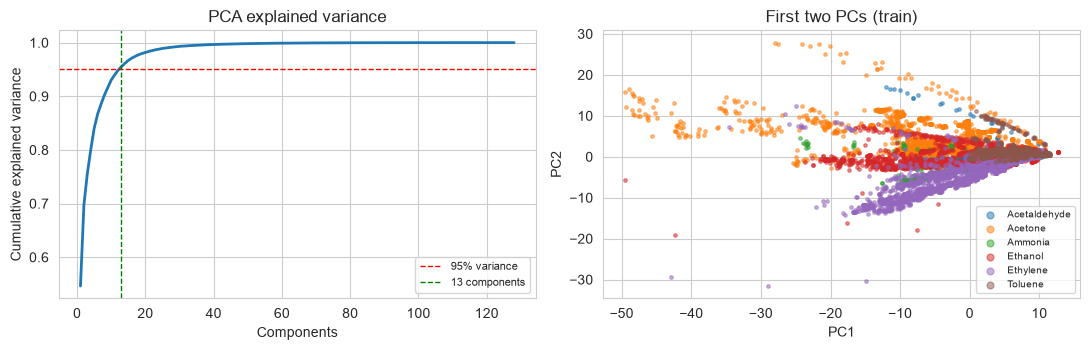

13 components capture 95% of the training-set variance (NB: variance retained is NOT classification accuracy).


In [14]:
scaler_v = StandardScaler().fit(X_train)
pca_full = PCA().fit(scaler_v.transform(X_train))
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(1, len(cum)+1), cum, lw=2)
ax[0].axhline(0.95, color="r", ls="--", lw=1, label="95% variance")
ax[0].axvline(n95, color="g", ls="--", lw=1, label=f"{n95} components")
ax[0].set_xlabel("Components"); ax[0].set_ylabel("Cumulative explained variance")
ax[0].set_title("PCA explained variance"); ax[0].legend(fontsize=8)
p2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(scaler_v.transform(X_train))
for g in np.unique(y_train):
    m = y_train == g
    ax[1].scatter(p2[m,0], p2[m,1], s=6, alpha=.5, label=g)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("First two PCs (train)")
ax[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()
print(f"{n95} components capture 95% of the training-set variance (NB: variance retained is NOT classification accuracy).")

## 9. Why these two algorithms? - a six-model screen

We screen six classical algorithms (Labs 05–09) under **two representations** - the original 128
standardised features and PCA(95%) - using the **same 3-fold CV on the training set** and macro-F1,
with scaling and PCA fit **inside each fold**. This answers both *which algorithms are strongest* and
*whether PCA helps each one*. The **test set is not used here** - this only informs *which two*
algorithms we carry forward. It is an exploratory baseline under default settings, not an exhaustive
hyper-parameter search.

In [15]:
def pca_pipe(model):            # reused by later cells - keep defined
    return Pipeline([("scale", StandardScaler()),
                     ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)), ("model", model)])
def orig_pipe(model):
    return Pipeline([("scale", StandardScaler()), ("model", model)])

screen = {"Logistic Regression": make_lr(),
          "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
          "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
          "Random Forest": make_rf_light(),
          "Gaussian Naive Bayes": GaussianNB(),
          "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)}
rows = []
for name, m in screen.items():
    for rep_name, pipe in [("Original (128)", orig_pipe(m)), ("PCA (95%)", pca_pipe(m))]:
        sc = cross_val_score(pipe, X_train, y_train, cv=CV3, scoring="f1_macro", n_jobs=-1)
        rows.append({"Algorithm": name, "Representation": rep_name,
                     "CV Macro-F1": round(sc.mean(), 4), "CV std": round(sc.std(), 4)})
screen_df = pd.DataFrame(rows)
comparison = screen_df.pivot(index="Algorithm", columns="Representation", values="CV Macro-F1")
comparison["PCA - Original"] = (comparison["PCA (95%)"] - comparison["Original (128)"]).round(4)
comparison = comparison.sort_values("Original (128)", ascending=False)
display(comparison)

Representation,Original (128),PCA (95%),PCA - Original
Algorithm,,,
Random Forest,0.9920,0.9877,-0.0043
K-Nearest Neighbors,0.9882,0.9828,-0.0054
Logistic Regression,0.9882,0.9083,-0.0799
SVM (RBF),0.9768,0.9296,-0.0472
Decision Tree,0.9578,0.9584,0.0006
Gaussian Naive Bayes,0.5690,0.6258,0.0568


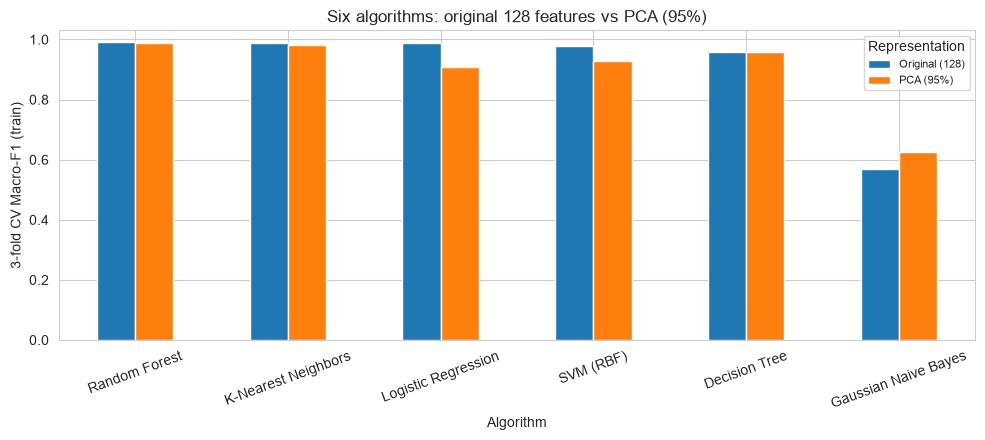

In [16]:
comparison[["Original (128)", "PCA (95%)"]].plot(kind="bar", figsize=(10, 4.5), rot=20)
plt.ylim(0, 1.03); plt.ylabel("3-fold CV Macro-F1 (train)")
plt.title("Six algorithms: original 128 features vs PCA (95%)")
plt.legend(title="Representation", fontsize=8); plt.tight_layout(); plt.show()

> **Decision (and hypotheses).** Random Forest ranks highest, so it is one choice. Gaussian
> Naive Bayes is weakest; *we hypothesise* its strong independence/Gaussian assumptions fit this
> data poorly. (The screen runs on PCA components, which are uncorrelated but not necessarily
> independent, so this is a hypothesis, not a demonstrated cause.) KNN scores well here but is
> non-interpretable; SVM is strong but slower and opaque. (We do not carry KNN or SVM into the
> drift study, so we make no claim about their temporal robustness.) The two-representation screen
> also shows PCA affects algorithms very differently: the linear and margin models (Logistic
> Regression, SVM) lose the most under PCA, the tree models are barely affected, and **Naive Bayes
> actually improves** - consistent with PCA decorrelating the features, which better fits its
> conditional-independence assumption (empirical support for the hypothesis above). We therefore keep **Random Forest** (best, non-linear, importances) and **Logistic
> Regression** (interpretable linear baseline, maximally *distinct* from RF, with coefficients as a
> second interpretability lens). These two are fixed as our headline pair from here on.

## 10. Algorithm background

**Logistic Regression (Member A)** - models each class's log-odds as a linear function of the
inputs (softmax for multiclass); interpretable coefficients, fast, probabilistic; linear boundaries.

**Random Forest (Member B)** - a bagged ensemble of decision trees using random feature subsets per
split; captures non-linear interactions and yields importances, at the cost of interpretability and
compute. Both use balanced class weights.

## 11. Feature-representation comparison (training CV, fully fold-safe)

Does **feature engineering** help? The six-model screen (Section 9) already gives the Original-128
and PCA numbers for Logistic Regression and Random Forest; here we add the **Engineered+Select(40)**
representation (`engineer(176) → scale → SelectKBest(ANOVA, 40) → model`) on the same CV folds and
place all three side by side. Everything is fit inside each fold (no leakage).

In [17]:
eng_rows = {}
for name, factory in [("Logistic Regression", make_lr), ("Random Forest", make_rf_light)]:
    pipe = Pipeline([("eng", FunctionTransformer(engineer_np)), ("scale", StandardScaler()),
                     ("select", SelectKBest(f_classif, k=40)), ("model", factory())])
    sc = cross_val_score(pipe, X_train, y_train, cv=CV3, scoring="f1_macro", n_jobs=-1)
    eng_rows[name] = round(sc.mean(), 4)
rep_compare = comparison.loc[["Logistic Regression", "Random Forest"], ["Original (128)", "PCA (95%)"]].copy()
rep_compare["Engineered+Select"] = pd.Series(eng_rows)
print("Representation comparison (training CV macro-F1):")
display(rep_compare.round(4))

Representation comparison (training CV macro-F1):


Representation,Original (128),PCA (95%),Engineered+Select
Algorithm,,,
Logistic Regression,0.9882,0.9083,0.9705
Random Forest,0.9920,0.9877,0.9898


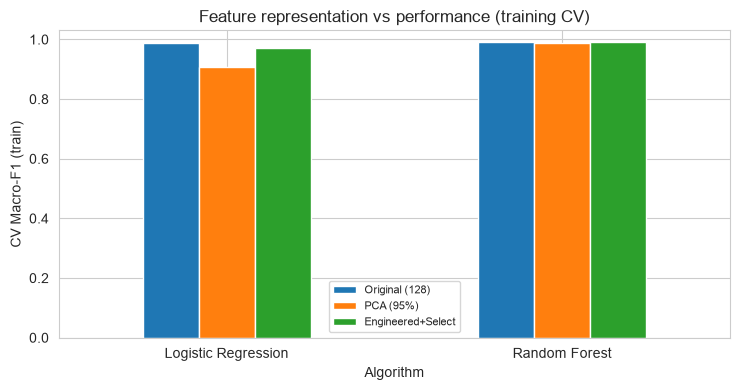

In [18]:
rep_compare.plot(kind="bar", figsize=(7.5, 4), rot=0); plt.ylim(0, 1.03)
plt.ylabel("CV Macro-F1 (train)"); plt.title("Feature representation vs performance (training CV)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 12. How many PCA components? - component sweep (training CV)

PCA is re-fit inside each fold for every component count (lighter forest used for speed).

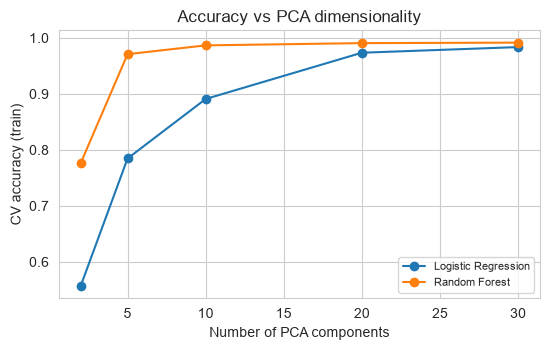

In [19]:
component_counts = [2, 5, 10, 20, 30]
sweep = {"Logistic Regression": [], "Random Forest": []}
for n in component_counts:
    for name, factory in [("Logistic Regression", make_lr), ("Random Forest", make_rf_light)]:
        pipe = Pipeline([("scale", StandardScaler()),
                         ("pca", PCA(n_components=n, random_state=RANDOM_STATE)), ("model", factory())])
        sweep[name].append(cross_val_score(pipe, X_train, y_train, cv=CV3, scoring="accuracy", n_jobs=-1).mean())
plt.figure(figsize=(5.6, 3.6))
for name in sweep: plt.plot(component_counts, sweep[name], marker="o", label=name)
plt.xlabel("Number of PCA components"); plt.ylabel("CV accuracy (train)")
plt.title("Accuracy vs PCA dimensionality"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 13. Hyper-parameter tuning (GridSearchCV on training CV)

Both models are tuned inside leakage-safe pipelines with 3-fold CV (macro-F1). We report the best
**cross-validated** score and parameters; the test set is still reserved for Section 14.

In [20]:
grids = {
 "Logistic Regression": (pca_pipe(make_lr()), {"model__C": [0.1, 1, 10]}),
 "Random Forest":       (pca_pipe(make_rf_light()),
                         {"model__n_estimators": [100, 200], "model__max_depth": [None, 20],
                          "model__min_samples_leaf": [2]}),
}
best_estimators = {}   # keep the fitted best estimator (refit on full train), not just params
rows = []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=CV3, n_jobs=-1, refit=True).fit(X_train, y_train)
    best_estimators[name] = gs.best_estimator_
    rows.append({"Model": name, "Best CV Macro-F1": round(gs.best_score_, 4), "Best params": str(gs.best_params_)})
pd.DataFrame(rows)

,Model,Best CV Macro-F1,Best params
0,Logistic Regression,0.9086,{'model__C': 10}
1,Random Forest,0.9886,"{'model__max_depth': 20, 'model__min_samples_l..."


## 14. Final evaluation on the untouched test set

We touch the test set once, reporting **two clearly separated objectives**:
- **Best predictive model** - the representation that scored highest in training CV (Section 11),
  which is **All (128)** for both algorithms.
- **PCA model (the required dimensionality-reduction study)** - the **tuned** `scale → PCA(0.95)
  → model` pipelines from Section 13 (`best_estimators`).

This is deliberately transparent: PCA is the assignment's mandated reduction technique, but it is
**not** the strongest representation here (clearly so for Logistic Regression), and we quantify that
trade-off rather than hide it. Note that 95% *variance* retained is not 95% *accuracy*.

In [21]:
classes = sorted(np.unique(y))
yb = label_binarize(y_test, classes=classes)
final = {
 ("All (128)",   "Logistic Regression"): Pipeline([("scale", StandardScaler()), ("model", make_lr())]),
 ("All (128)",   "Random Forest"):       Pipeline([("scale", StandardScaler()), ("model", make_rf())]),
 ("PCA (tuned)", "Logistic Regression"): best_estimators["Logistic Regression"],
 ("PCA (tuned)", "Random Forest"):       best_estimators["Random Forest"],
}
fitted_final, rows = {}, []
for (rep_name, name), est in final.items():
    if rep_name.startswith("All"):        # best_estimators are already refit by GridSearchCV
        est.fit(X_train, y_train)
    fitted_final[(rep_name, name)] = est
    pred, proba = est.predict(X_test), est.predict_proba(X_test)
    rows.append({"Representation": rep_name, "Model": name,
                 "Accuracy": round(accuracy_score(y_test, pred), 4),
                 "Macro-F1": round(f1_score(y_test, pred, average="macro"), 4),
                 "Balanced-Acc": round(balanced_accuracy_score(y_test, pred), 4),
                 "ROC-AUC(ovr)": round(roc_auc_score(yb, proba, average="macro", multi_class="ovr"), 4)})
print("Final test results (All-128 = best CV representation; PCA = required reduction):")
final_table = pd.DataFrame(rows); display(final_table)

Final test results (All-128 = best CV representation; PCA = required reduction):


,Representation,Model,Accuracy,Macro-F1,Balanced-Acc,ROC-AUC(ovr)
0,All (128),Logistic Regression,0.9917,0.9915,0.9915,0.9984
1,All (128),Random Forest,0.9934,0.9931,0.9929,0.9994
2,PCA (tuned),Logistic Regression,0.9362,0.9298,0.9311,0.9915
3,PCA (tuned),Random Forest,0.9914,0.9910,0.9906,0.9998


### 14.1 Final model comparison chart (Figure C)

A grouped bar of the test metrics (full 0-1 axis, not truncated). The two All-128 models are
near-identical; the only visible gap is PCA Logistic Regression, which confirms the accuracy cost
of the mandated dimensionality reduction for the linear model.

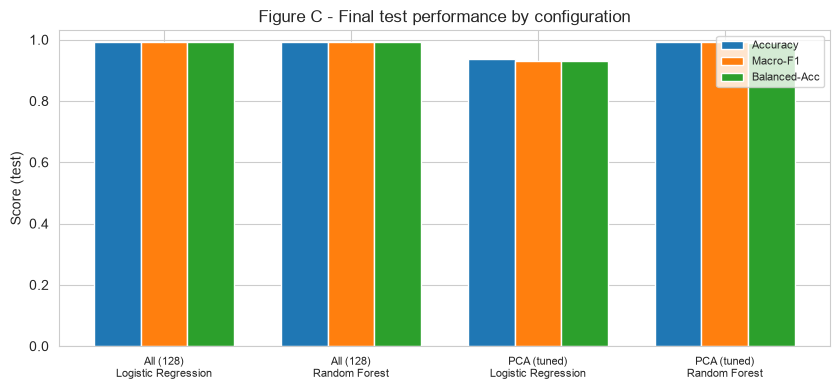

In [22]:
mets = ["Accuracy", "Macro-F1", "Balanced-Acc"]
xpos = np.arange(len(final_table)); w = 0.25
plt.figure(figsize=(8.5, 4))
for k, met in enumerate(mets):
    plt.bar(xpos + k*w, final_table[met].values, w, label=met)
plt.xticks(xpos + w, [f"{r}\n{m}" for r, m in zip(final_table["Representation"], final_table["Model"])], fontsize=8)
plt.ylim(0, 1.03); plt.ylabel("Score (test)")
plt.title("Figure C - Final test performance by configuration"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

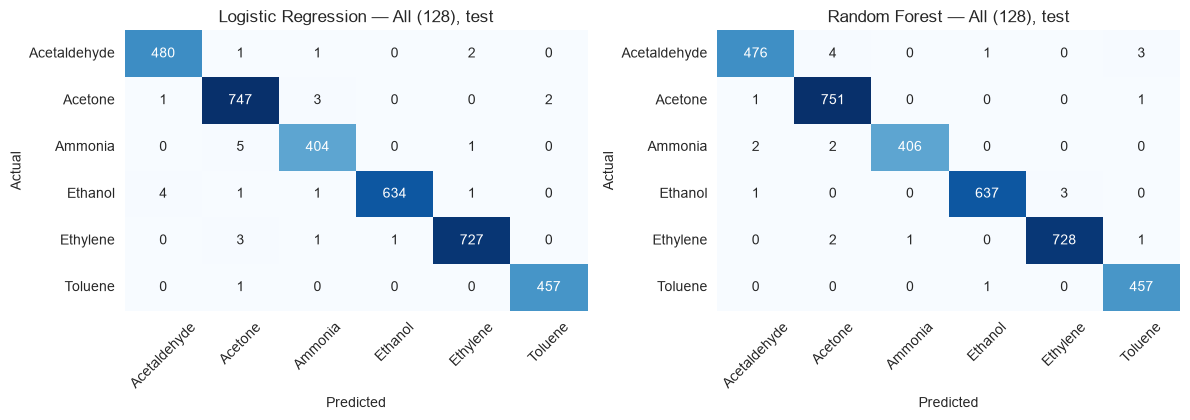

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    est = fitted_final[("All (128)", name)]
    cm = confusion_matrix(y_test, est.predict(X_test), labels=classes)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=classes, yticklabels=classes)
    ax.set_title(f"{name} — All (128), test"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 15. Interpretability - two lenses (fit on training data)

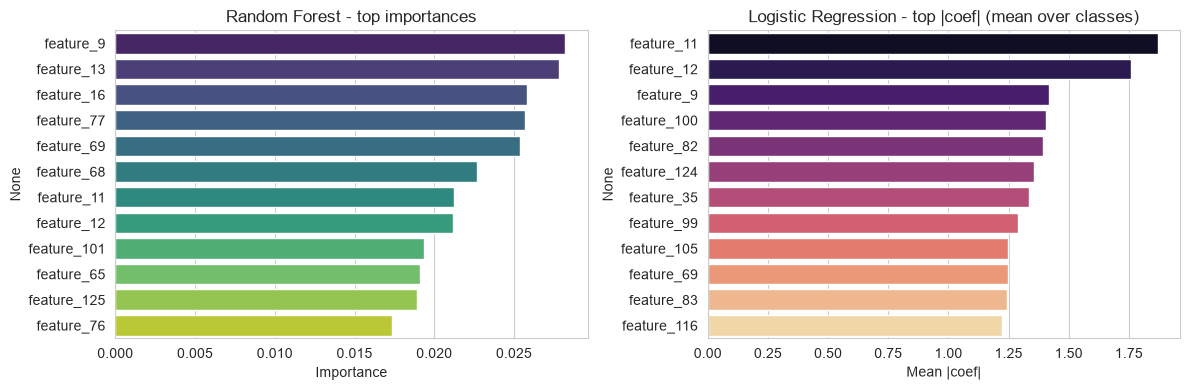

In [24]:
rf_est = fitted_final[("All (128)", "Random Forest")].named_steps["model"]
lr_est = fitted_final[("All (128)", "Logistic Regression")].named_steps["model"]
imp    = pd.Series(rf_est.feature_importances_, index=FEATURES).sort_values(ascending=False).head(12)
lr_imp = pd.Series(np.abs(lr_est.coef_).mean(0), index=FEATURES).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Random Forest - top importances"); ax[0].set_xlabel("Importance")
sns.barplot(x=lr_imp.values, y=lr_imp.index, hue=lr_imp.index, palette="magma", legend=False, ax=ax[1])
ax[1].set_title("Logistic Regression - top |coef| (mean over classes)"); ax[1].set_xlabel("Mean |coef|")
plt.tight_layout(); plt.show()

## 16. Learning curves - training-set size sensitivity

If the cross-validation curve has plateaued, more data *of the same kind* would help little.
This speaks only to the random-split distribution; it cannot by itself predict behaviour on later
chronological batches.

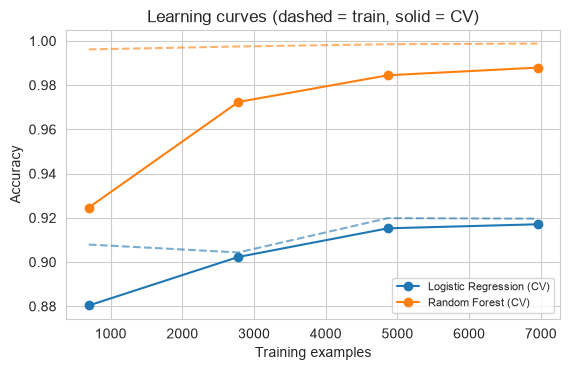

In [25]:
plt.figure(figsize=(5.8, 3.8))
for name, factory, color in [("Logistic Regression", make_lr, "tab:blue"),
                             ("Random Forest", make_rf_light, "tab:orange")]:
    ts, tr, va = learning_curve(pca_pipe(factory()), X_train, y_train,
                                train_sizes=np.linspace(0.1, 1.0, 4), cv=CV3,
                                scoring="accuracy", n_jobs=-1)
    plt.plot(ts, tr.mean(1), "--", color=color, alpha=.6)
    plt.plot(ts, va.mean(1), "-o", color=color, label=f"{name} (CV)")
plt.xlabel("Training examples"); plt.ylabel("Accuracy")
plt.title("Learning curves (dashed = train, solid = CV)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 17. The key experiment - performance under sensor drift (true chronology)

The random-split protocol mixes all time periods. Here we use the **true acquisition batches**:
train on early batches, test on later ones, with scaling and PCA fit on the **training batches
only**. We report several configurations, per-batch accuracy, and the train-vs-future gap.

**Interpretation is cautious:** a train/future gap is *consistent with* overfitting but can also
reflect genuine distribution shift (sensor ageing, changing gas concentrations). We treat these as
hypotheses, not proofs, and note the confounders.

In [26]:
def drift_eval(train_batches, test_batches):
    tr = np.isin(batch, train_batches); te = np.isin(batch, test_batches)
    out = {}
    for name, factory in [("Logistic Regression", make_lr), ("Random Forest", make_rf)]:
        pipe = pca_pipe(factory()).fit(X.values[tr], y[tr]); pred = pipe.predict(X.values[te])
        out[(name, "Acc")]      = round(accuracy_score(y[te], pred), 4)
        out[(name, "Macro-F1")] = round(f1_score(y[te], pred, labels=classes, average="macro", zero_division=0), 4)
        out[(name, "Bal-Acc")]  = round(balanced_accuracy_score(y[te], pred), 4)
    return out

configs = {"Train 1-5 / test 6-10": ([1,2,3,4,5], [6,7,8,9,10]),
           "Train 1-3 / test 4-10": ([1,2,3],     [4,5,6,7,8,9,10]),
           "Train 1-6 / test 7-10": ([1,2,3,4,5,6],[7,8,9,10])}
drift_df = pd.DataFrame({k: drift_eval(*v) for k, v in configs.items()}).T
print("Later-batch performance. Context: these drift models use the PCA pipeline, whose random-split\n"
      "      TEST accuracy was ~0.936 (LR) / ~0.991 (RF) - a different protocol, not a matched baseline):")
display(drift_df)
wins = {k: ("LR" if drift_df.loc[k, ("Logistic Regression", "Acc")] >= drift_df.loc[k, ("Random Forest", "Acc")] else "RF")
        for k in configs}
print("Higher accuracy by configuration:", wins)

Later-batch performance. Context: these drift models use the PCA pipeline, whose random-split
      TEST accuracy was ~0.936 (LR) / ~0.991 (RF) - a different protocol, not a matched baseline):


Logistic Regression                  Random Forest  \
                                      Acc Macro-F1 Bal-Acc           Acc   
Train 1-5 / test 6-10              0.6251   0.5895  0.6264        0.5569   
Train 1-3 / test 4-10              0.5944   0.5167  0.5719        0.5879   
Train 1-6 / test 7-10              0.6041   0.5865  0.6176        0.6189   

                                        
                      Macro-F1 Bal-Acc  
Train 1-5 / test 6-10   0.4936  0.5343  
Train 1-3 / test 4-10   0.5242  0.5666  
Train 1-6 / test 7-10   0.6071  0.6208

Higher accuracy by configuration: {'Train 1-5 / test 6-10': 'LR', 'Train 1-3 / test 4-10': 'LR', 'Train 1-6 / test 7-10': 'RF'}


Train-vs-future gap (consistent with overfitting, but also with distribution shift):
  Logistic Regression    train=0.988  later unweighted-mean=0.600  pooled=0.625
  Random Forest          train=0.999  later unweighted-mean=0.532  pooled=0.557

Per-class detail on later batches 6-10 (trained on 1-5):

--- Logistic Regression ---
              precision    recall  f1-score   support

Acetaldehyde      0.294     0.521     0.376      1481
     Acetone      0.949     0.594     0.730      2057
     Ammonia      0.905     0.823     0.862      1210
     Ethanol      0.498     0.922     0.647      1854
    Ethylene      0.940     0.896     0.918      1921
     Toluene      0.750     0.002     0.003      1754

    accuracy                          0.625     10277
   macro avg      0.723     0.626     0.589     10277
weighted avg      0.733     0.625     0.591     10277


--- Random Forest ---
              precision    recall  f1-score   support

Acetaldehyde      0.383     0.219     0.278    

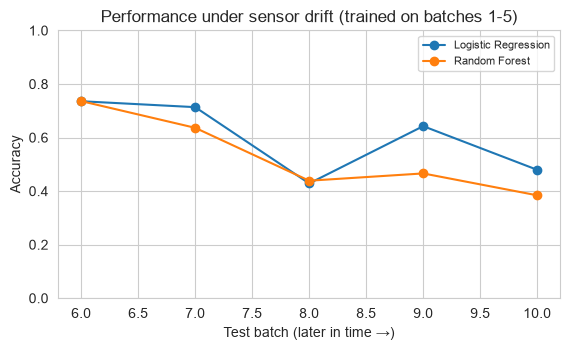

In [27]:
# Per-batch degradation + train-vs-future gap (trained on batches 1-5)
tr = np.isin(batch, [1,2,3,4,5])
fitted = {name: pca_pipe(f()).fit(X.values[tr], y[tr])
          for name, f in [("Logistic Regression", make_lr), ("Random Forest", make_rf)]}
print("Train-vs-future gap (consistent with overfitting, but also with distribution shift):")
for name, m in fitted.items():
    tr_acc = accuracy_score(y[tr], m.predict(X.values[tr]))
    later = [accuracy_score(y[batch==b], m.predict(X.values[batch==b])) for b in [6,7,8,9,10]]
    sizes = [np.sum(batch==b) for b in [6,7,8,9,10]]
    print(f"  {name:22s} train={tr_acc:.3f}  later unweighted-mean={np.mean(later):.3f}  pooled={np.average(later,weights=sizes):.3f}")
te15 = np.isin(batch, [6,7,8,9,10])
print("\nPer-class detail on later batches 6-10 (trained on 1-5):")
for name, m in fitted.items():
    print(f"\n--- {name} ---")
    print(classification_report(y[te15], m.predict(X.values[te15]), labels=classes, zero_division=0, digits=3))

plt.figure(figsize=(5.8, 3.6))
for name, m in fitted.items():
    plt.plot([6,7,8,9,10], [accuracy_score(y[batch==b], m.predict(X.values[batch==b])) for b in [6,7,8,9,10]],
             marker="o", label=name)
plt.xlabel("Test batch (later in time \u2192)"); plt.ylabel("Accuracy"); plt.ylim(0, 1)
plt.title("Performance under sensor drift (trained on batches 1-5)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 17.1 Per-gas recall across later batches (Figure D)

Overall accuracy hides *which* gases fail under drift. This heatmap shows each gas's recall on each
later batch (models trained on batches 1-5). Blank cells mean the gas is **absent** from that batch
(undefined recall), not zero recall - an important distinction given the uneven class composition.

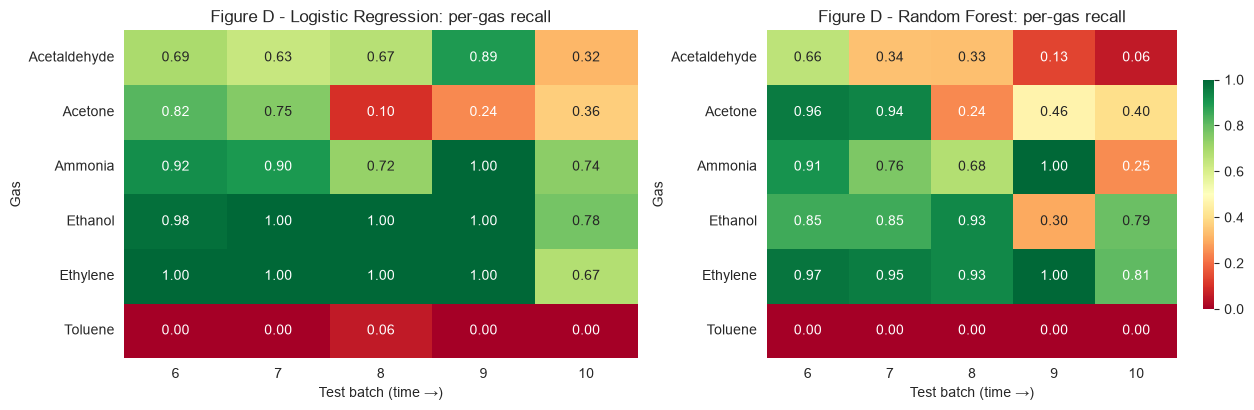

In [28]:
from sklearn.metrics import recall_score
later_batches = [6, 7, 8, 9, 10]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (name, m) in zip(axes, fitted.items()):
    M = np.full((len(classes), len(later_batches)), np.nan)
    for j, b in enumerate(later_batches):
        mk = batch == b; yt = y[mk]
        rec = recall_score(yt, m.predict(X.values[mk]), labels=classes, average=None, zero_division=0)
        present = set(yt)
        for i, g in enumerate(classes):
            if g in present: M[i, j] = rec[i]
    sns.heatmap(M, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax,
                xticklabels=later_batches, yticklabels=classes, mask=np.isnan(M),
                cbar=(ax is axes[-1]), cbar_kws={"shrink": .7})
    ax.set_title(f"Figure D - {name}: per-gas recall"); ax.set_xlabel("Test batch (time \u2192)"); ax.set_ylabel("Gas")
plt.tight_layout(); plt.show()

## 18. Results, discussion and future work

**How accuracy was obtained.** Standardisation gives Logistic Regression a clear, leakage-free CV
improvement (Section 5.1); the engineered/selected and PCA representations retain strong CV
performance with far fewer features (Sections 11 - 12); tuning adds a small CV gain (Section 13).
learning curves (Section 16) indicate performance has largely plateaued with training-set size on the random-split distribution.

**Dimensionality.** ~13 components capture 95% of the variance. Random Forest keeps almost all its
accuracy on that compressed space; Logistic Regression loses more, plausibly because
variance-maximising directions need not be the most class-discriminative and LR is restricted to
linear boundaries. *Note: 95% variance retained is not 95% accuracy.*

**Algorithm comparison (random split).** Both models are strong; Random Forest leads on every
metric. The six-model screen - run on both original and PCA features - shows performance is
**representation-dependent**: the linear and margin models (Logistic Regression, SVM) lose the most
under PCA, the tree models are barely affected, and Naive Bayes actually improves, consistent with
PCA removing the linear correlation among the features (a partial step toward the independence it
assumes, though decorrelation is not full statistical independence). As an exploratory baseline under
default settings, the screen indicates why the unselected algorithms were weaker here, without
claiming they could not improve with tuning.

**Sensor drift (true chronology).** Accuracy falls sharply on later batches for both models.
Across the three chronological configurations the ranking is **period-dependent**: Logistic
Regression had higher accuracy in two of the three settings and Random Forest in the third, so
**neither model is universally more drift-robust**. The degradation is consistent with temporal
distribution shift, but these experiments cannot isolate sensor ageing from differences in class
composition, gas concentration and acquisition conditions across batches; a train-vs-future gap is
likewise *consistent with* overfitting but does not prove it. The robust, defensible conclusion is
that a **random split substantially overstates real-world performance**, and that the preferred
model depends on the deployment period rather than on a single leaderboard number. A per-class view (Figure D) sharpens this: **Toluene recall collapses to near zero** on later batches
for both models. The training batches 1 - 5 contain only ~79 Toluene samples (and batches 3 - 5 none),
a **plausible contributor**; but these experiments do not isolate class coverage from sensor ageing,
concentration or other acquisition differences, so we read it as an important limitation of temporal
generalisation rather than a single established cause. Median concentration also differs across
batches (e.g. batch 6 is markedly lower), a further confounder (Section 4.2).

**Limitations.** Single laboratory and sensor array; engineered sensor features (not raw signals);
very uneven batch sizes; results depend on the 95% variance threshold and the chosen splits; the
train/future gap cannot by itself prove overfitting versus distribution shift. The three
chronological configurations have **overlapping** later periods and were examined during
development, so they are temporal **sensitivity analyses**, not pristine prospective tests; and
scarce training coverage of some gases (notably Toluene) confounds per-class drift conclusions.

**Future work.** Drift-aware strategies (periodic retraining, domain adaptation, batch ensembles);
wider and nested hyper-parameter search for less optimistic estimates; alternative reductions (LDA,
kernel PCA); and using the concentration information.

**Conclusion.** On the random-split evaluation both algorithms perform strongly and Random Forest
achieves the better classification scores. On chronologically later batches, performance drops
substantially for both models; Logistic Regression is higher in two of the three temporal splits
and Random Forest in the third, so the evidence does **not** establish either model as consistently
more robust to temporal change. The study's clearest contribution is methodological: shuffled
test results alone are insufficient to judge deployment performance when sensor measurements shift
across acquisition periods.